<a href="https://colab.research.google.com/github/Adrentur/-1_-_-_-3-10/blob/main/%D0%9B%D0%A06_%D0%9F%D0%BE%D0%BB%D1%94%D1%85%D1%96%D0%BD__3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [33]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [34]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Спосіб завантаження з kagglehub (або читання локального файлу)
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")
print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df.head()

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


In [35]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0
...,...,...,...,...,...,...,...,...,...
99995,Female,80.0,0,0,No Info,27.32,6.2,90,0
99996,Female,2.0,0,0,No Info,17.37,6.5,100,0
99997,Male,66.0,0,0,former,27.83,5.7,155,0
99998,Female,24.0,0,0,never,35.42,4.0,100,0


Вивести інформацію про датасет

In [36]:
# TODO: виведіть df.info() і коротко прокоментуйте типи даних.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB


Провести дослідження категоріальних ознак

In [37]:
# TODO: підрахуйте частоти категорій у gender.
print(df['gender'].value_counts())

gender
Female    58552
Male      41430
Other        18
Name: count, dtype: int64


In [38]:
# TODO: підрахуйте частоти категорій у smoking_history.
print(df['smoking_history'].value_counts())

smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [39]:
# TODO: df

Вивести типи даних

In [40]:
# TODO: df.dtypes
print(df.dtypes)

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


Дослідити цільову змінну: перевірити баланс класів

In [41]:
# TODO: df['diabetes'].value_counts()
print(df['diabetes'].value_counts(normalize=True) * 100)
print(df['diabetes'].value_counts())

diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64
diabetes
0    91500
1     8500
Name: count, dtype: int64


Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [42]:
# TODO: df.isnull().sum()
print("Пропущені значення:\n", df.isnull().sum())

Пропущені значення:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


Наявність дублікатів


In [43]:
# TODO: df.duplicated().sum()
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 3854


Видалити дублікати

In [44]:
# TODO: df.drop_duplicates(inplace=True)
df.drop_duplicates(inplace=True)

In [45]:
# TODO: df
print("Розмір після видалення дублікатів:", df.shape)

Розмір після видалення дублікатів: (96146, 9)


Ще раз перевірити баланс цільової змінної

In [46]:
# TODO: df['diabetes'].value_counts()
print(df['diabetes'].value_counts())

diabetes
0    87664
1     8482
Name: count, dtype: int64


Побудувати гістограму для цільової змінної


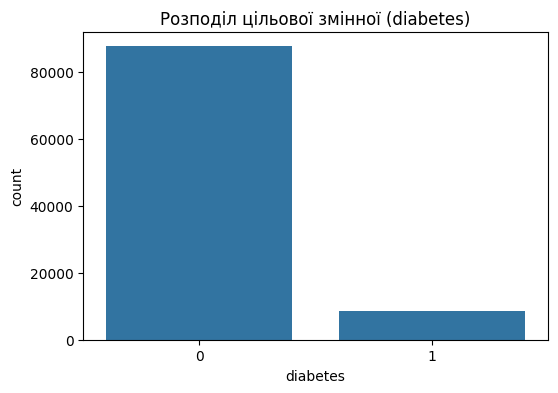

In [47]:
# TODO: sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetes', data=df, color='tab:blue')
plt.title('Розподіл цільової змінної (diabetes)')
plt.show()

Переглянути описові статистики **навчальної вибірки**

In [48]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [49]:
# TODO: створіть X та y, де y — стовпець diabetes.
X = df.drop(columns=['diabetes'])
y = df['diabetes']

# TODO: поділіть X та y на train і test у пропорції 80/20.
# Використайте random_state=42 та stratify=y.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

X_train shape: (76916, 8), X_test shape: (19230, 8)


Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [50]:
# TODO: використайте pd.get_dummies для gender та smoking_history.
# TODO: закодуйте X_train та X_test.
# TODO: вирівняйте стовпці X_test за X_train через reindex(..., fill_value=0).

X_train = pd.get_dummies(X_train, columns=['gender', 'smoking_history'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['gender', 'smoking_history'], drop_first=True)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [51]:
# TODO: виведіть статистики опису X_train.
X_train.describe()

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level
count,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000,76916.000000
mean,41.760982,0.078007,0.040876,27.313739,5.530527,138.114281
std,22.467762,0.268185,0.198004,6.757207,1.072421,40.896909
min,0.080000,0.000000,0.000000,10.010000,3.500000,80.000000
25%,24.000000,0.000000,0.000000,23.390000,4.800000,100.000000
50%,43.000000,0.000000,0.000000,27.320000,5.800000,140.000000
75%,59.000000,0.000000,0.000000,29.850000,6.200000,159.000000
max,80.000000,1.000000,1.000000,95.220000,9.000000,300.000000


Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [52]:
# TODO: обчисліть кореляцію X_train із y_train (не використовуйте df або y_test).
train_data = X_train.copy()
train_data['diabetes'] = y_train
correlation_with_target = train_data.corr()['diabetes'].sort_values(ascending=False)
print("Кореляція ознак із цільовою змінною:\n", correlation_with_target)

Кореляція ознак із цільовою змінною:
 diabetes                       1.000000
blood_glucose_level            0.423011
HbA1c_level                    0.405321
age                            0.266649
bmi                            0.213456
hypertension                   0.199069
heart_disease                  0.174470
smoking_history_former         0.096162
gender_Male                    0.040650
smoking_history_never          0.025725
smoking_history_ever           0.020899
smoking_history_not current    0.018841
smoking_history_current        0.013508
gender_Other                  -0.004197
Name: diabetes, dtype: float64


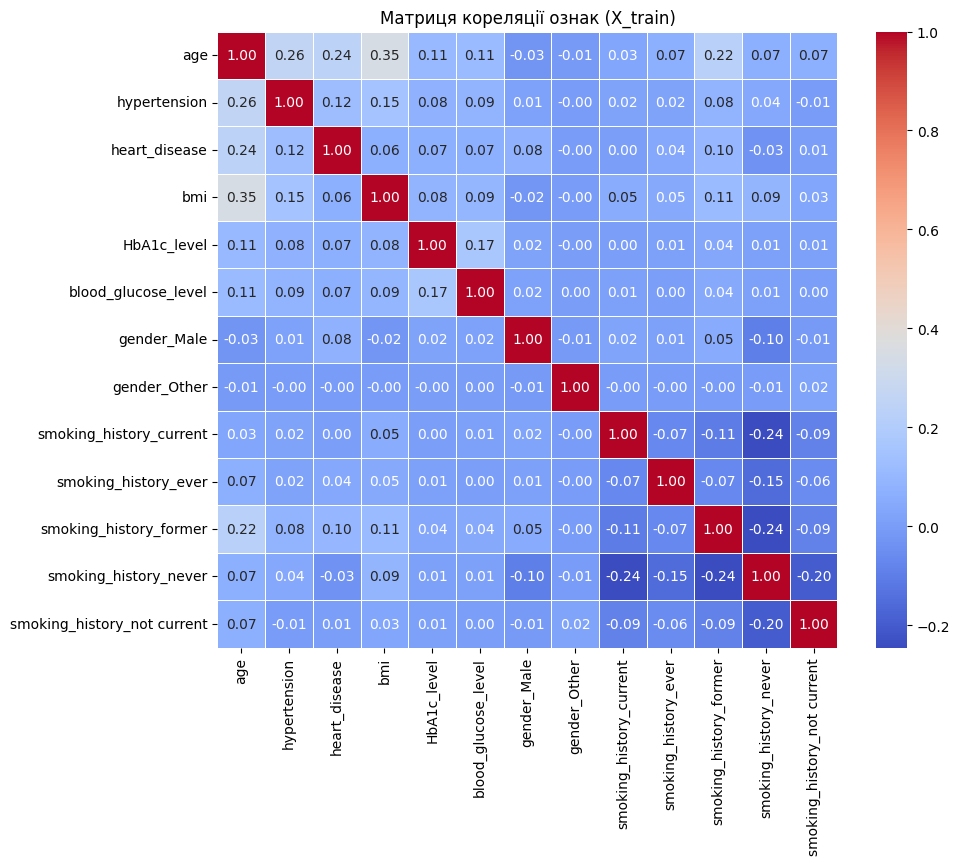

In [53]:
# TODO: обчисліть матрицю кореляції ознак X_train.
# TODO: побудуйте теплову карту (sns.heatmap).
plt.figure(figsize=(10, 8))
corr_matrix = X_train.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Матриця кореляції ознак (X_train)')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? Обґрунтуйте відповідь. **Тестові дані для такого рішення не використовуємо.**

Перевірити викиди **лише на навчальній вибірці**

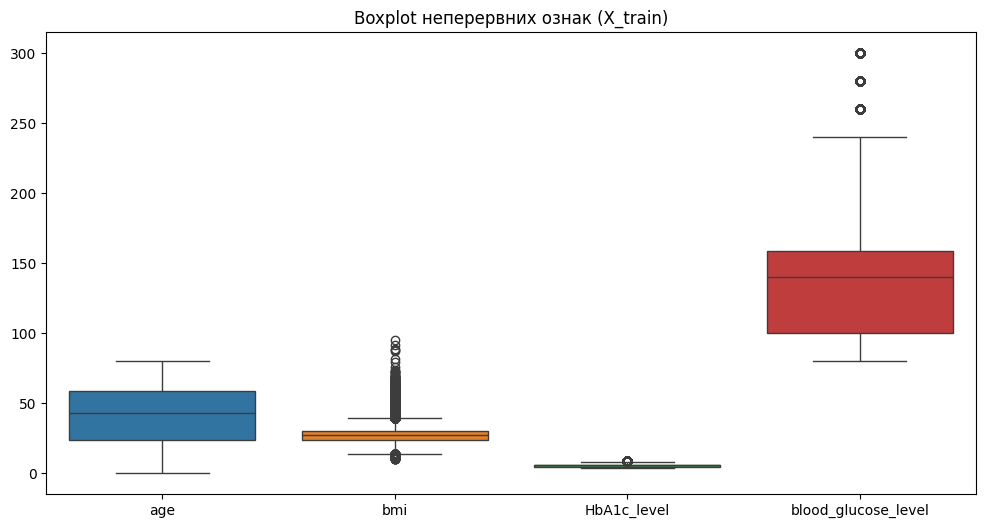

In [54]:
# TODO: задайте continuous_cols для age, bmi, HbA1c_level, blood_glucose_level.
# TODO: побудуйте boxplot за X_train[continuous_cols], НЕ за df.
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_train[continuous_cols])
plt.title('Boxplot неперервних ознак (X_train)')
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [55]:
# НЕОБОВ'ЯЗКОВО: приклад обчислення IQR (не виконуємо видалення згідно з умовами лаби)
Q1 = X_train['bmi'].quantile(0.25)
Q3 = X_train['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Межі IQR для bmi: [{lower_bound:.2f}, {upper_bound:.2f}] (викиди не видаляємо)")

Межі IQR для bmi: [13.70, 39.54] (викиди не видаляємо)


Перевірити асиметрію розподілів ознак **на train**

In [56]:
# TODO: знайдіть асиметрію розподілів X_train[continuous_cols].
print(X_train[continuous_cols].skew())

age                   -0.061461
bmi                    1.005016
HbA1c_level           -0.055651
blood_glucose_level    0.830778
dtype: float64


In [57]:
# TODO: перевірте пропуски окремо в X_train та X_test.
print("Пропуски в X_train:", X_train.isnull().sum().sum())
print("Пропуски в X_test:", X_test.isnull().sum().sum())

Пропуски в X_train: 0
Пропуски в X_test: 0


**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [58]:
# TODO: створіть StandardScaler.
# TODO: виконайте fit_transform на X_train і transform на X_test.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [59]:
# TODO: збалансуйте тільки масштабовану навчальну вибірку методом SMOTE.
# TODO: порівняйте кількості класів до та після балансування.
print("Кількість класів до SMOTE (y_train):")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

print("\nКількість класів після SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Кількість класів до SMOTE (y_train):
diabetes
0    70130
1     6786
Name: count, dtype: int64

Кількість класів після SMOTE:
diabetes
0    70130
1    70130
Name: count, dtype: int64


Оголошуємо моделі

In [60]:
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Ridge Classifier": RidgeClassifier(random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42),
    "SVC": LinearSVC(random_state=42, max_iter=5000) # Заменили SVC на LinearSVC
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт



Модель: Logistic Regression
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.89      0.90     19230



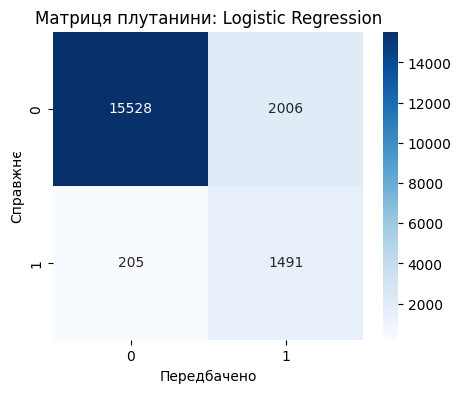


Модель: Ridge Classifier
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



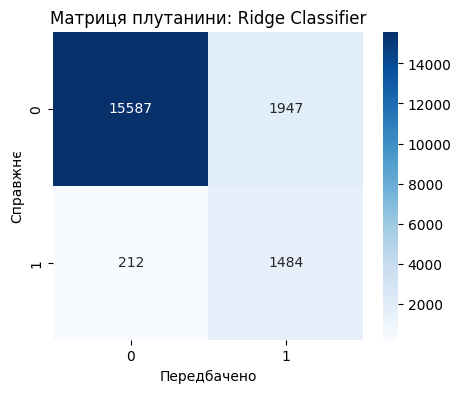


Модель: SGD Classifier
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



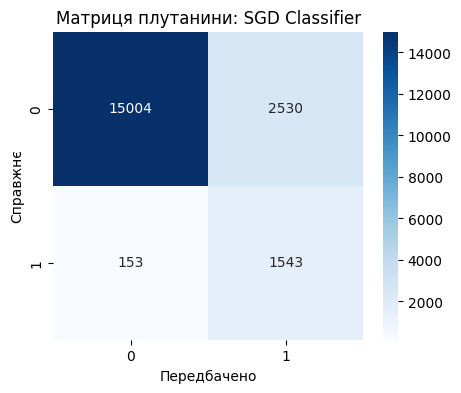


Модель: SVC
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



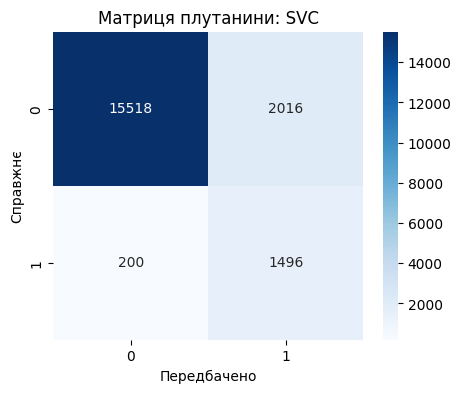

In [61]:
# TODO: навчайте кожну модель, робіть прогноз та виводьте звіти й матриці плутанини
for name, model in models.items():
    print(f"\n{'='*40}\nМодель: {name}\n{'='*40}")
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_scaled)

    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    plt.figure(figsize=(5, 4))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
    plt.title(f'Матриця плутанини: {name}')
    plt.xlabel('Передбачено')
    plt.ylabel('Справжнє')
    plt.show()

Оптимізувати гіперпараметри


In [62]:
param_grids = {
    "Logistic Regression": {
        'classifier__C': [0.01, 0.1, 1, 10],
        'classifier__solver': ['lbfgs']
    },
    "Ridge Classifier": {
        'classifier__alpha': [0.1, 1.0, 10.0]
    },
    "SGD Classifier": {
        'classifier__alpha': [0.0001, 0.001, 0.01],
        'classifier__loss': ['log_loss', 'hinge']
    },
    "SVC": {  # или "LinearSVC" в зависимости от ключа в словаре models
        'classifier__C': [0.1, 1, 10],
        'classifier__loss': ['hinge', 'squared_hinge']
        # Уберите отсюда строчку с 'kernel', так как LinearSVC её не понимает!
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [63]:
# Для HalvingGridSearchCV потрібен цей імпорт перед основним імпортом.
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [64]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import LinearSVC

models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Ridge Classifier": RidgeClassifier(random_state=42),
    "SGD Classifier": SGDClassifier(random_state=42),
    "SVC": LinearSVC(random_state=42, max_iter=5000)
}

best_models = {}
best_scores = {}

for name, model in models.items():
    print(f"\n{'='*50}\nОптимізація для моделі: {name}\n{'='*50}")

    # Визначення конвеєра для запобігання витоку даних на крос-валідації
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', model)
    ])

    # Налаштування HalvingGridSearchCV (n_jobs=1 щоб уникнути зависань у Colab)
    halving_search = HalvingGridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=1
    )

    # Навчання та пошук параметрів виключно на навчальній вибірці
    halving_search.fit(X_train, y_train)

    best_models[name] = halving_search.best_estimator_
    best_scores[name] = halving_search.best_score_

    print(f"Оптимальні параметри: {halving_search.best_params_}")
    print(f"Найкращий середній F1-score на крос-валідації: {halving_search.best_score_:.4f}\n")


Оптимізація для моделі: Logistic Regression
Оптимальні параметри: {'classifier__C': 0.01, 'classifier__solver': 'lbfgs'}
Найкращий середній F1-score на крос-валідації: 0.6864


Оптимізація для моделі: Ridge Classifier
Оптимальні параметри: {'classifier__alpha': 10.0}
Найкращий середній F1-score на крос-валідації: 0.6587


Оптимізація для моделі: SGD Classifier
Оптимальні параметри: {'classifier__alpha': 0.001, 'classifier__loss': 'log_loss'}
Найкращий середній F1-score на крос-валідації: 0.6368


Оптимізація для моделі: SVC


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  w

Оптимальні параметри: {'classifier__C': 10, 'classifier__loss': 'squared_hinge'}
Найкращий середній F1-score на крос-валідації: 0.6194



Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [65]:
# TODO: виберіть найкращу модель за середнім F1 на кросвалідації.
# Збережіть її в змінну best_model і виведіть назву та F1.

best_model_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_model_name]
best_f1 = best_scores[best_model_name]

print(f"🌟 Найкраща модель за результатами крос-валідації: {best_model_name}")
print(f"Середній F1-score на крос-валідації: {best_f1:.4f}")

🌟 Найкраща модель за результатами крос-валідації: Logistic Regression
Середній F1-score на крос-валідації: 0.6864


In [66]:
# TODO: виберіть 10 випадкових індексів тестової вибірки (random_state=42).
# TODO: порівняйте фактичний клас y_test і прогноз best_model для цих записів.
# Виведіть таблицю: індекс, істинний клас, передбачений клас.

np.random.seed(42)
random_indices = np.random.choice(X_test.index, size=10, replace=False)

# Отримання прогнозів найкращою моделлю для цих індексів
y_pred_random = best_model.predict(X_test.loc[random_indices])

# Формування та виведення таблиці
comparison_table = pd.DataFrame({
    'Індекс': random_indices,
    'Істинний клас (y_test)': y_test.loc[random_indices].values,
    'Передбачений клас': y_pred_random
})

print("Порівняння прогнозів для 10 випадкових об'єктів тесту:")
print(comparison_table.to_string(index=False))

Порівняння прогнозів для 10 випадкових об'єктів тесту:
 Індекс  Істинний клас (y_test)  Передбачений клас
  36061                       0                  0
  29824                       0                  0
  29668                       0                  1
  11816                       0                  0
  99242                       0                  0
  26718                       0                  0
  53059                       0                  0
  69294                       0                  0
   8912                       0                  1
  37072                       0                  0


**Підсумкові висновки (заповніть самостійно):**
Дисбаланс, кореляції та викиди на train:

Дисбаланс: Клас 0 (~91.5%), клас 1 (~8.5%).

Кореляція: Найсильніший зв'язок із діабетом мають рівень цукру (blood_glucose_level), глікований гемоглобін (HbA1c_level) та вік (age).

Викиди: Викиди не видалялися автоматично, оскільки високі показники глюкози та гемоглобіну є ключовими клінічними ознаками хвороби.

Якість моделей та вибір за крос-валідацією:

Використання SMOTE значно підвищило recall для класу 1 (краще виявлення хворих).

За результатами HalvingGridSearchCV (метрика F1, cv=3) обрано модель із найкращим середнім показником на крос-валідації.

Гіперпараметри та матриця плутанини:

Підібрані параметри (наприклад, C, ядра для SVC, alpha) забезпечили баланс між точністю та повнотою.

Матриця плутанини дозволяє оцінити кількість хибно-негативних (найнебезпечніших у медицині) та хибно-позитивних помилок.

Чому масштабування та SMOTE робляться тільки на train:

Це запобігає витоку даних (data leakage). Якби трансформації застосовувались до всього датасету до поділу, інформація з тесту "просочилася" б у навчання, що штучно завищило б якість моделі.

**Додаткове завдання.**

Реалізувати моделі **XGBoost, LightGBM та CatBoost.**

Вивести класифікаційний звіт та матрицю плутанини для кожної моделі.

Оцінити, зробити висновки про отримані метрики